## Busqueda de patrones

In [5]:
def PatternCount(Text, Pattern):
    count = 0
    for i in range(len(Text)-len(Pattern)+1):
        if Text[i:i+len(Pattern)] == Pattern:
            count += 1
    return count  

In [6]:
Text = "GACCATACTG"
Pattern = "ATA"

In [7]:
import random as random
def DNA(N):
    secuencia = ""
    for n in range(N):
        secuencia += (random.choice(["A","T","G","C"]))
    return secuencia

Text = DNA(20)
print(Text)

GACCGTGATCTCGCGGGCTT


In [8]:
Pattern = "ATA"
PatternCount(Text, Pattern)

0

## Busqueda de patrones y mapa de frecuencias

In [9]:
def FrequencyMap(Text, k):
    freq = {}
    n = len(Text)       
    for i in range(n-k+1):
        Pattern = Text[i:i+k]
        if Pattern not in freq:
            freq[Pattern] = 1
        elif Pattern in freq:
            freq[Pattern] += 1
    return freq


In [10]:
#Text = "CGATATATCCATAG"
k=10
FrequencyMap(Text,k)

{'GACCGTGATC': 1,
 'ACCGTGATCT': 1,
 'CCGTGATCTC': 1,
 'CGTGATCTCG': 1,
 'GTGATCTCGC': 1,
 'TGATCTCGCG': 1,
 'GATCTCGCGG': 1,
 'ATCTCGCGGG': 1,
 'TCTCGCGGGC': 1,
 'CTCGCGGGCT': 1,
 'TCGCGGGCTT': 1}

## Entropía de Shannon en análisis de secuencias

En el análisis de secuencias, no solo interesa identificar patrones repetidos, 
sino también cuantificar el grado de **desorden o incertidumbre** en la distribución de *k-mer*.  

La **entropía de Shannon** proporciona una medida de la información asociada a una distribución de probabilidades $\{p_i\}$:

$$
H = - \sum_i p_i \, \log_2 p_i
$$

donde cada $p_i$ corresponde a la probabilidad de aparición de un *k-mer* en la secuencia.  

- Si un único motivo domina ($p_i \approx 1$), la entropía es baja → la secuencia es más **predecible**.  
- Si las probabilidades están repartidas de forma uniforme, la entropía es alta → la secuencia es más **aleatoria**.  

Esta herramienta permite caracterizar regiones de ADN/ARN o proteínas según su grado de orden o diversidad.
En el caso del ADN, una entropía baja puede indicar regiones **funcionales o reguladoras** (por ejemplo, promotores o sitios de unión a proteínas), 
mientras que una entropía alta suele corresponder a regiones **aleatorias o espaciadoras**, sin una función específica clara.

In [11]:
import math

def ShannonEntropy(Text, k):
    freq = FrequencyMap(Text, k)  # usamos función anterior
    total = sum(freq.values())
    entropy = 0
    for Pattern in freq:
        p = freq[Pattern] / total
        entropy -= p * math.log2(p)
    return entropy


In [12]:
#Text = "CGATATATCCATAG"
k = 3
print("Mapa de frecuencias:", FrequencyMap(Text, k))
print("Entropía de Shannon:", ShannonEntropy(Text, k))


Mapa de frecuencias: {'GAC': 1, 'ACC': 1, 'CCG': 1, 'CGT': 1, 'GTG': 1, 'TGA': 1, 'GAT': 1, 'ATC': 1, 'TCT': 1, 'CTC': 1, 'TCG': 1, 'CGC': 1, 'GCG': 1, 'CGG': 1, 'GGG': 1, 'GGC': 1, 'GCT': 1, 'CTT': 1}
Entropía de Shannon: 4.169925001442312


## Busqueda de patrones más frecuentes

In [13]:
def FrequentWords(Text, k): # devolve as palabras máis frecuentes
    words = []
    freq = FrequencyMap(Text, k)
    m = max(freq.values())
    for key in freq:
        if freq[key] == m:
            pattern = key
            words.append(pattern)
    return [words, m]

In [14]:
# Vibrio cholerae oriC k = 10
#Text = "ACGTTGCATGTCGCATGATGCATGAGAGCT"
k = 3
fw = FrequentWords(Text, k)
print(fw[0],'\ncon frecuencia', fw[1])

['GAC', 'ACC', 'CCG', 'CGT', 'GTG', 'TGA', 'GAT', 'ATC', 'TCT', 'CTC', 'TCG', 'CGC', 'GCG', 'CGG', 'GGG', 'GGC', 'GCT', 'CTT'] 
con frecuencia 1


## Cadenas reverso-complementarias

In [15]:
def Reverse(Pattern): # dálle a volta á cadea
    rev = ''
    for letter in Pattern:
        rev = letter + rev    
    return rev

def Complement(Pattern): # escribe o complementario ( A<-->T , C<-->G )
    basepairs = {"A":"T", "G":"C", "T":"A", "C":"G"}
    complement = ""
    for base in Pattern:
        complement += basepairs.get(base)
    return complement

def ReverseComplement(Pattern): # aplica ambas operacións anteriores
    Pattern = Reverse(Pattern) 
    Pattern = Complement(Pattern) 
    return Pattern

In [16]:
Pattern = 'ACGTTGCATGTCGCATGATGCATGAGAGCT'
ReverseComplement(Pattern)

'AGCTCTCATGCATCATGCGACATGCAACGT'

## Patrones y localizacion

In [17]:
def PatternMatching(Pattern, Genome):
    positions = [] 
    for i in range(len(Genome)-len(Pattern)+1):
        if Genome[i:i+len(Pattern)] == Pattern:
           positions.append(i)
    return positions

In [18]:
with open("Vibrio_cholerae.txt") as f:
    Genome = f.read()
print(Genome)

...


In [21]:
Pattern = 'CTTGATCAT'
PatternMatching(Pattern, Genome)

[60039,
 98409,
 129189,
 152283,
 152354,
 152411,
 163207,
 197028,
 200160,
 357976,
 376771,
 392723,
 532935,
 600085,
 622755,
 1065555]

In [22]:
ReverseComplement('ATGATCAAG')

'CTTGATCAT'

## CLUMP FINDING PROBLEM
Búsqueda de “clumps” tipo "ATGATCAAG"/"CTTGATCAT" or "CCTACCACC"/"GGTGGTAGG" 

In [23]:
#OJO el PatternCount definido arriba no va bien, para que funcione correctamente con SymbolArray 
#hay que invertir los parametros de entrada Pattern y text
def PatternCount(Pattern, Text):
    count = 0
    for i in range(len(Text)-len(Pattern)+1):
        if Text[i:i+len(Pattern)] == Pattern:
            count += 1
    return count 

def SymbolArray(Genome, symbol):
    array = {}
    n = len(Genome)
    ExtendedGenome = Genome + Genome[0:n//2]
    for i in range(n):
        array[i] = PatternCount(symbol, ExtendedGenome[i:i+(n//2)])
    return array

In [24]:
SymbolArray('AAAAGGGG','A')

{0: 4, 1: 3, 2: 2, 3: 1, 4: 0, 5: 1, 6: 2, 7: 3}

PROBLEMA!!!!!!!!!!

In [ ]:
%%time
SymbolArray(Genome,'A')  

In [25]:
def FasterSymbolArray(Genome, symbol):
    array = {}
    n = len(Genome)
    ExtendedGenome = Genome + Genome[0:n//2]

    array[0] = PatternCount(symbol, Genome[0:n//2])

    for i in range(1, n):
        array[i] = array[i-1]
        if ExtendedGenome[i-1] == symbol:
            array[i] = array[i]-1
        if ExtendedGenome[i+(n//2)-1] == symbol:
            array[i] = array[i]+1
    return array

In [26]:
FasterSymbolArray('AAAAGGGG','A')

{0: 4, 1: 3, 2: 2, 3: 1, 4: 0, 5: 1, 6: 2, 7: 3}

In [27]:
%%time
FasterSymbolArray(Genome,'A')

CPU times: total: 516 ms
Wall time: 514 ms


{0: 143965,
 1: 143965,
 2: 143965,
 3: 143964,
 4: 143964,
 5: 143964,
 6: 143964,
 7: 143963,
 8: 143963,
 9: 143963,
 10: 143963,
 11: 143964,
 12: 143963,
 13: 143963,
 14: 143963,
 15: 143963,
 16: 143964,
 17: 143964,
 18: 143964,
 19: 143964,
 20: 143965,
 21: 143966,
 22: 143965,
 23: 143965,
 24: 143965,
 25: 143966,
 26: 143966,
 27: 143966,
 28: 143966,
 29: 143966,
 30: 143965,
 31: 143964,
 32: 143963,
 33: 143963,
 34: 143964,
 35: 143964,
 36: 143965,
 37: 143965,
 38: 143966,
 39: 143966,
 40: 143966,
 41: 143966,
 42: 143966,
 43: 143965,
 44: 143966,
 45: 143966,
 46: 143966,
 47: 143966,
 48: 143966,
 49: 143965,
 50: 143966,
 51: 143966,
 52: 143966,
 53: 143966,
 54: 143967,
 55: 143967,
 56: 143967,
 57: 143968,
 58: 143969,
 59: 143968,
 60: 143968,
 61: 143968,
 62: 143968,
 63: 143969,
 64: 143968,
 65: 143968,
 66: 143967,
 67: 143966,
 68: 143966,
 69: 143966,
 70: 143966,
 71: 143966,
 72: 143967,
 73: 143966,
 74: 143966,
 75: 143966,
 76: 143966,
 77: 1439

## DIFERENCIAS G y C

In [28]:
def SkewArray(Genome):
    Skew = [0]
    n = len(Genome)
    for i in range(n):
        count = 0
        if Genome[i] == 'G':
            Skew.append(Skew[i]+1)
        elif Genome[i] == 'C':
            Skew.append(Skew[i]-1)
        else:
            Skew.append(Skew[i])
     
    return Skew

In [29]:
SkewArray('CATGGGCATCGGCCATACGCC')

[0, -1, -1, -1, 0, 1, 2, 1, 1, 1, 0, 1, 2, 1, 0, 0, 0, 0, -1, 0, -1, -2]

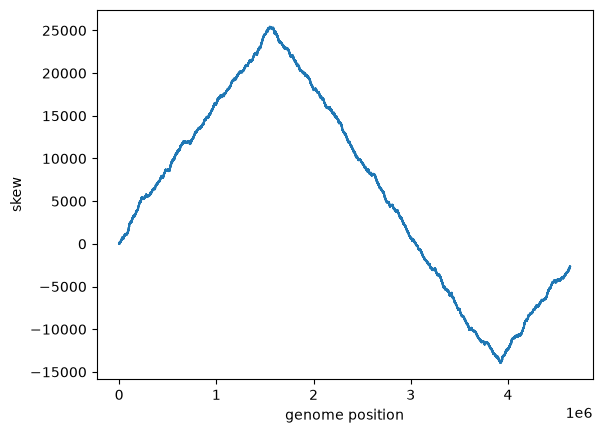

In [30]:
import matplotlib.pyplot as plt
with open('e_coli.txt') as file:
    genome = file.read()
skew = SkewArray(genome)
plt.plot(skew)
plt.xlabel('genome position')
plt.ylabel('skew')
plt.show()

In [31]:
def MinimumSkew(Genome): 
    array = SkewArray(Genome)
    positions = []
    count = 0
    minarray = min(array)
    for i in array:
        if i == minarray:
            positions.append(count)
        count +=1
    return positions

In [32]:
MinimumSkew('TAAAGACTGCCGAGAGGCCAACACGAGTGCTAGAACGAGGGGCGTAAACGCGGGTCCGAT')

[11, 24]

## DISTANCIA DE HAMMING

In [33]:
def HammingDistance(p, q): # esta distancia mide a diferenza xenica entre varias cadeas, i.e., mide unha tolerancia de compatibilidade
    count = 0
    n = len(p)
    for i in range(n):
        if p[i] != q[i]:
            count = count + 1
    return count

In [34]:
HammingDistance('GGGCCGTTGGT','GGACCGTTGAC')

3

In [35]:
def ApproximatePatternMatching(Text, Pattern,d):
    positions = []
    count = 0
    t=Text
    p=Pattern
    k = len(p)
    l = len(t)
    for i in range(0,l-k+1):
        if HammingDistance((t[i:k+i]), p) <= d:
            positions.append(count)
        count += 1

    return positions

In [36]:
Pattern ='ATTCTGGA'
Text ='CGCCCGAATCCAGAACGCATTCCCATATTTCGGGACCACTGGCCTCCACGGTACGGACGTCAATCAAAT'
d = 2
ApproximatePatternMatching(Text, Pattern,d)

[27]

In [37]:
def read_seq(file):
  
    with open(file,"r") as f:
        seq = f.read()   
    seq =  seq.replace('\n','')    
    sep = seq.replace('\r','')
    return seq


def translate(seq):    
    table = {
    'ATA':'I', 'ATC':'I', 'ATT':'I', 'ATG':'M',
    'ACA':'T', 'ACC':'T', 'ACG':'T', 'ACT':'T',
    'AAC':'N', 'AAT':'N', 'AAA':'K', 'AAG':'K',
    'AGC':'S', 'AGT':'S', 'AGA':'R', 'AGG':'R',
    'CTA':'L', 'CTC':'L', 'CTG':'L', 'CTT':'L',
    'CCA':'P', 'CCC':'P', 'CCG':'P', 'CCT':'P',
    'CAC':'H', 'CAT':'H', 'CAA':'Q', 'CAG':'Q',
    'CGA':'R', 'CGC':'R', 'CGG':'R', 'CGT':'R',
    'GTA':'V', 'GTC':'V', 'GTG':'V', 'GTT':'V',
    'GCA':'A', 'GCC':'A', 'GCG':'A', 'GCT':'A',
    'GAC':'D', 'GAT':'D', 'GAA':'E', 'GAG':'E',
    'GGA':'G', 'GGC':'G', 'GGG':'G', 'GGT':'G',
    'TCA':'S', 'TCC':'S', 'TCG':'S', 'TCT':'S',
    'TTC':'F', 'TTT':'F', 'TTA':'L', 'TTG':'L',
    'TAC':'Y', 'TAT':'Y', 'TAA':'_', 'TAG':'_',
    'TGC':'C', 'TGT':'C', 'TGA':'_', 'TGG':'W',
    }
    
    protein = "" 

    if len(seq) % 3 == 0:
        for i in range(0,len(seq),3):
            codon = seq[i : i+3]
            protein += table[codon]
    return protein   


In [38]:
prt = read_seq('protein.txt')
dna = read_seq('dna.txt')

In [39]:
protein=translate(dna[20:938])

In [40]:
protein

'MSTHDTSLKTTEEVAFQIILLCQFGVGTFANVFLFVYNFSPISTGSKQRPRQVILRHMAVANALTLFLTIFPNNMMTFAPIIPQTDLKCKLEFFTRLVARSTNLCSTCVLSIHQFVTLVPVNSGKGILRASVTNMASYSCYSCWFFSVLNNIYIPIKVTGPQLTDNNNNSKSKLFCSTSDFSVGIVFLRFAHDATFMSIMVWTSVSMVLLLHRHCQRMQYIFTLNQDPRGQAETTATHTILMLVVTFVGFYLLSLICIIFYTYFIYSHHSLRHCNDILVSGFPTISPLLLTFRDPKGPCSVFFNC_'

In [41]:
prt == protein

False

In [42]:
prt

'MSTHDTSLKTTEEVAFQIILLCQFGVGTFANVFLFVYNFSPISTGSKQRPRQVILRHMAVANALTLFLTIFPNNMMTFAPIIPQTDLKCKLEFFTRLVARSTNLCSTCVLSIHQFVTLVPVNSGKGILRASVTNMASYSCYSCWFFSVLNNIYIPIKVTGPQLTDNNNNSKSKLFCSTSDFSVGIVFLRFAHDATFMSIMVWTSVSMVLLLHRHCQRMQYIFTLNQDPRGQAETTATHTILMLVVTFVGFYLLSLICIIFYTYFIYSHHSLRHCNDILVSGFPTISPLLLTFRDPKGPCSVFFNC'

In [43]:
protein=translate(dna[20:935])

In [44]:
prt == protein

True

###  Complejidad lingüística en secuencias biológicas

En el análisis de secuencias de ADN o proteínas, un concepto básico es el de **_k-mer_**, que representa un fragmento consecutivo de longitud *k* dentro de la secuencia. Por ejemplo, en la secuencia:

```
ATGCG
```

los *k*-mers de longitud 3 son: `ATG`, `TGC`, `GCG`.

Al recorrer toda la secuencia, se obtiene el conjunto de todos los *k*-mers posibles. Si una secuencia contiene muchos fragmentos repetidos (por ejemplo, `AAAAAA`), el número de *k*-mers distintos será pequeño; si, por el contrario, está compuesta por combinaciones variadas de letras (bases o aminoácidos), el número de *k*-mers distintos será alto.

La **complejidad lingüística** cuantifica esta diversidad combinatoria. Se define como la fracción de *k*-mers distintos observados respecto al número máximo de *k*-mers posibles. Matemáticamente:

$$
C_k = \frac{N_\text{observados}(k)}{N_\text{posibles}(k)}
$$

donde:
- $N_\text{observados}(k)$ es el número de *k*-mers distintos encontrados en la secuencia.
- $N_\text{posibles}(k) = \min(4^k,\; L - k + 1)$ en el caso del ADN (porque hay 4 bases posibles: A, T, C, G).

Una secuencia completamente aleatoria tenderá a una complejidad cercana a 1, mientras que una secuencia altamente repetitiva mostrará valores bajos. Este indicador es útil para detectar regiones con **redundancia estructural**, **microsatélites** (pequeñas repeticiones periódicas de pocos nucleótidos, típicas de regiones no codificantes) o **restricciones evolutivas** (limitaciones impuestas por la función o estructura de la molécula) en el ADN. Desde un punto de vista físico, puede interpretarse como una medida de la **diversidad estadística de configuraciones** dentro de una cadena biopolimérica.



Introduce el número de bases de la secuencia:  99



Secuencia generada (99 bases):
GGAGTCACCACTTGGTGGCAACTTGCGAACTAGCACTTTGAGACAGTGTATTAGAATGCGTCGGATGATCCCCGGAAGTGTTTACCTGCTTCGAACGCG

Complejidad global: 0.957


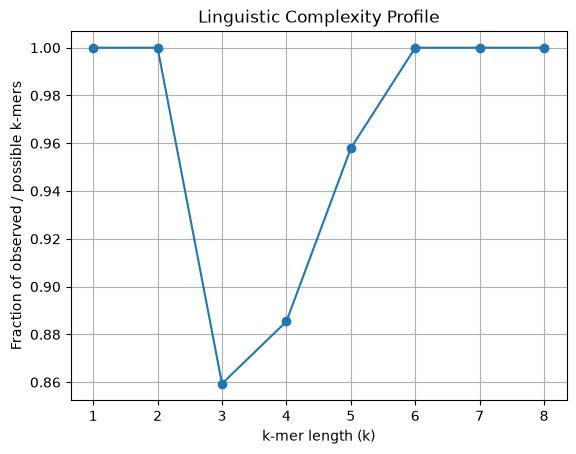

In [50]:
#  Cálculo de la complejidad lingüística con generación automática de secuencia

import random
import matplotlib.pyplot as plt

def generar_secuencia(longitud):
    """Genera una secuencia aleatoria de ADN con bases A, T, G, C."""
    bases = ['A', 'T', 'G', 'C']
    return ''.join(random.choice(bases) for _ in range(longitud))

def kmer_set(seq, k):
    """Devuelve el conjunto de k-mers distintos presentes en la secuencia."""
    return {seq[i:i+k] for i in range(len(seq)-k+1)}

def linguistic_complexity(seq, k_max=8):
    """
    Calcula la fracción de k-mers observados respecto a los posibles
    y la complejidad global de la secuencia.
    """
    seq = seq.upper()
    Ks, obs, poss, fracs = [], [], [], []
    for k in range(1, k_max+1):
        observed = len(kmer_set(seq, k))
        possible = min(4**k, len(seq)-k+1 if len(seq)>=k else 0)
        if possible == 0:
            continue
        Ks.append(k)
        obs.append(observed)
        poss.append(possible)
        fracs.append(observed/possible)
    global_complexity = sum(obs)/sum(poss)
    return Ks, fracs, global_complexity




L = int(input("Introduce el número de bases de la secuencia: "))


seq = generar_secuencia(L)
print(f"\nSecuencia generada ({L} bases):\n{seq}\n")


Ks, fracs, C_global = linguistic_complexity(seq, k_max=8)


print(f"Complejidad global: {C_global:.3f}")

plt.plot(Ks, fracs, marker='o')
plt.xlabel("k-mer length (k)")
plt.ylabel("Fraction of observed / possible k-mers")
plt.title("Linguistic Complexity Profile")
plt.grid(True)
plt.show()


###  Perfil hidrofóbico de una proteína

Las proteínas están formadas por cadenas de aminoácidos, algunos de los cuales son **hidrofóbicos** (tienden a evitar el agua) y otros **hidrofílicos** (prefieren el contacto con el solvente).  

El grado de hidrofobicidad de cada residuo puede cuantificarse mediante la **escala de Kyte–Doolittle**, que asigna a cada aminoácido un valor numérico (positivo = hidrofóbico, negativo = hidrofílico).  

Al representar el valor promedio de hidrofobicidad dentro de una ventana móvil a lo largo de la secuencia, se obtiene un **perfil hidrofóbico**.  
Este perfil permite identificar:
- regiones internas o enterradas (picos positivos),
- regiones expuestas al solvente (valores negativos),
- y posibles **hélices transmembrana** (segmentos largos con alta hidrofobicidad).

Desde un punto de vista físico, estos perfiles reflejan variaciones locales en la **energía libre de interacción con el medio acuoso**, que condicionan el plegamiento y la estabilidad de la proteína.


In [ ]:
#  Perfil hidrofóbico (Kyte–Doolittle)

import random
import matplotlib.pyplot as plt

# Escala de Kyte–Doolittle (1982)
hydropathy = {
    'I': 4.5, 'V': 4.2, 'L': 3.8, 'F': 2.8, 'C': 2.5, 'M': 1.9,
    'A': 1.8, 'G': -0.4, 'T': -0.7, 'S': -0.8, 'W': -0.9,
    'Y': -1.3, 'P': -1.6, 'H': -3.2, 'E': -3.5, 'Q': -3.5,
    'D': -3.5, 'N': -3.5, 'K': -3.9, 'R': -4.5
}

def generar_proteina(longitud):
    """Genera una secuencia aleatoria de aminoácidos."""
    aminoacidos = list(hydropathy.keys())
    return ''.join(random.choice(aminoacidos) for _ in range(longitud))

def hydrophobic_profile(seq, window=9):
    """Calcula el perfil hidrofóbico promedio a lo largo de la secuencia."""
    seq = seq.upper()
    profile = []
    for i in range(len(seq) - window + 1):
        values = [hydropathy.get(a, 0) for a in seq[i:i+window]]
        profile.append(sum(values)/window)
    return profile



L = int(input("Introduce el número de residuos de la proteína: "))
protein = generar_proteina(L)

print(f"\nSecuencia generada ({L} residuos):\n{protein}\n")

window = 9
profile = hydrophobic_profile(protein, window)


plt.plot(profile, color='purple')
plt.axhline(0, color='gray', linestyle='--')
plt.title("Hydrophobicity profile (Kyte–Doolittle)")
plt.xlabel(f"Residue position (window size = {window})")
plt.ylabel("Average hydropathy")
plt.grid(True)
plt.show()
